In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import pairwise_distances

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)


In [2]:
df = pd.read_csv("customer_data.csv")

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
# Parse enrollment date and derive tenure when available
if "Dt_Customer" in df.columns:
    dt = pd.to_datetime(df["Dt_Customer"], dayfirst=True, errors="coerce")
    if dt.notna().any():
        reference_date = dt.max()
        df["Customer_Tenure_Days"] = (reference_date - dt).dt.days
    df = df.drop(columns=["Dt_Customer"])

# Derive interpretable customer features when source columns exist
if "Year_Birth" in df.columns:
    df["Age"] = 2026 - pd.to_numeric(df["Year_Birth"], errors="coerce")
    df.loc[(df["Age"] < 18) | (df["Age"] > 100), "Age"] = np.nan
if all(c in df.columns for c in ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]):
    spend_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
    df["Total_Spending"] = df[spend_cols].apply(pd.to_numeric, errors="coerce").sum(axis=1)
if all(c in df.columns for c in ["Kidhome", "Teenhome"]):
    df["Children"] = pd.to_numeric(df["Kidhome"], errors="coerce") + pd.to_numeric(df["Teenhome"], errors="coerce")
if all(c in df.columns for c in ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]):
    cmp_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]
    df["Total_Campaigns_Accepted"] = df[cmp_cols].apply(pd.to_numeric, errors="coerce").sum(axis=1)

id_cols = [c for c in df.columns if c.strip().lower() in {"id", "customerid", "customer_id", "unnamed: 0"}]
# Drop constant columns and obvious identifiers from modeling only
print("Rows after duplicate removal:", len(df))
print("Potential identifier columns excluded from modeling:", id_cols)


Rows after duplicate removal: 200
Potential identifier columns excluded from modeling: ['ID']


Numerical columns: ['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response', 'Customer_Tenure_Days', 'Age', 'Total_Spending', 'Children', 'Total_Campaigns_Accepted']
Categorical columns: ['Education', 'Marital_Status']


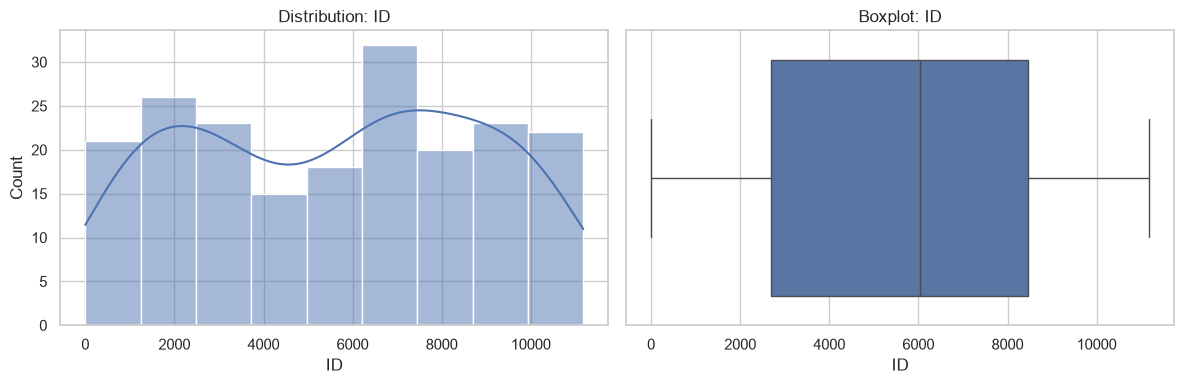

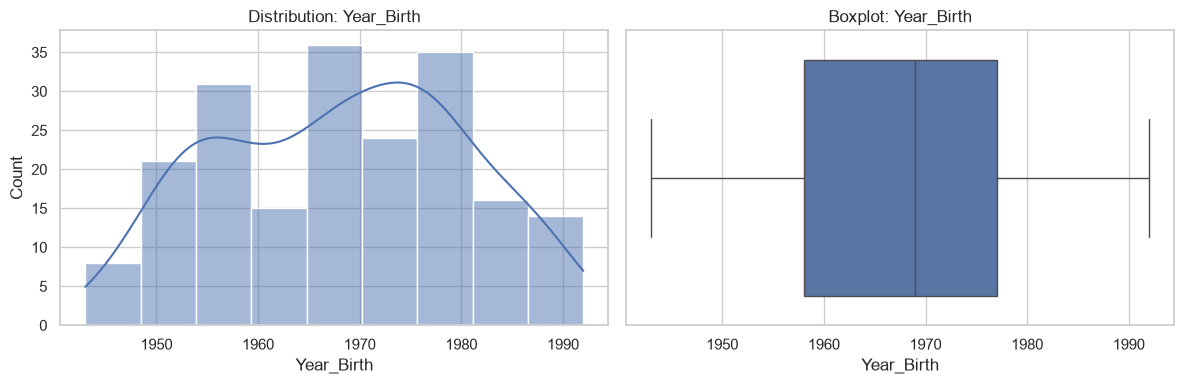

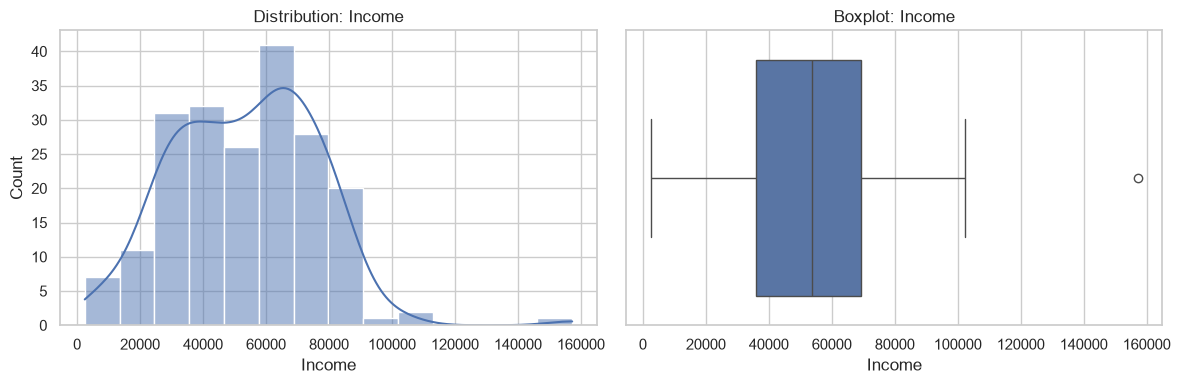

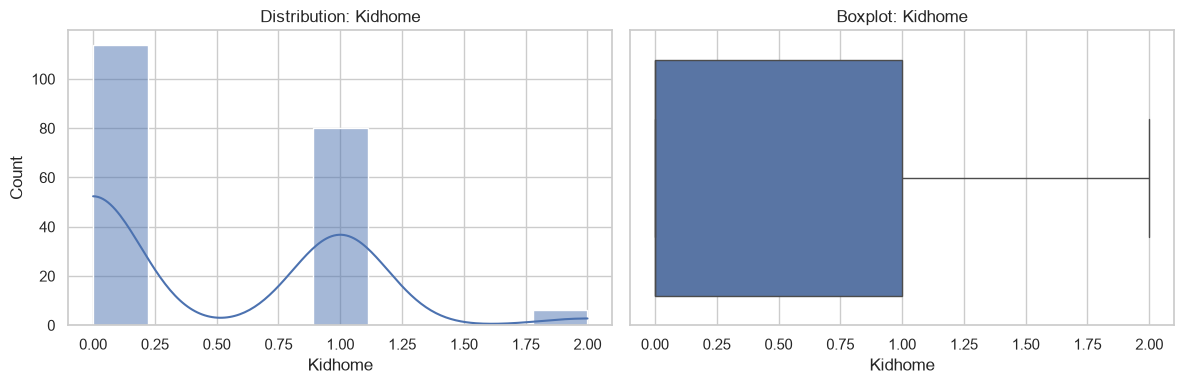

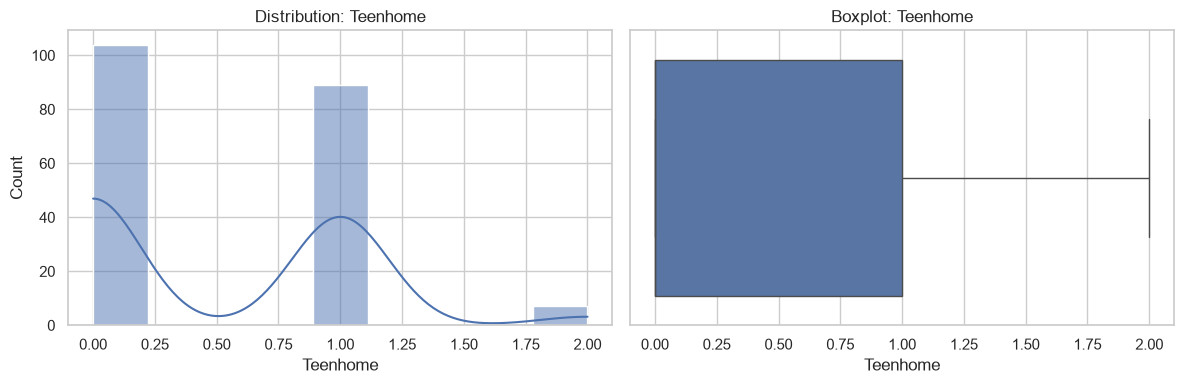

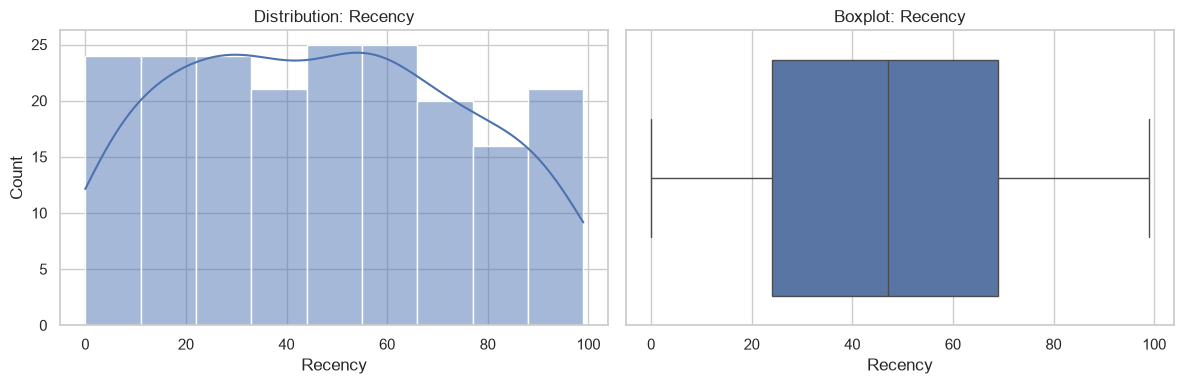

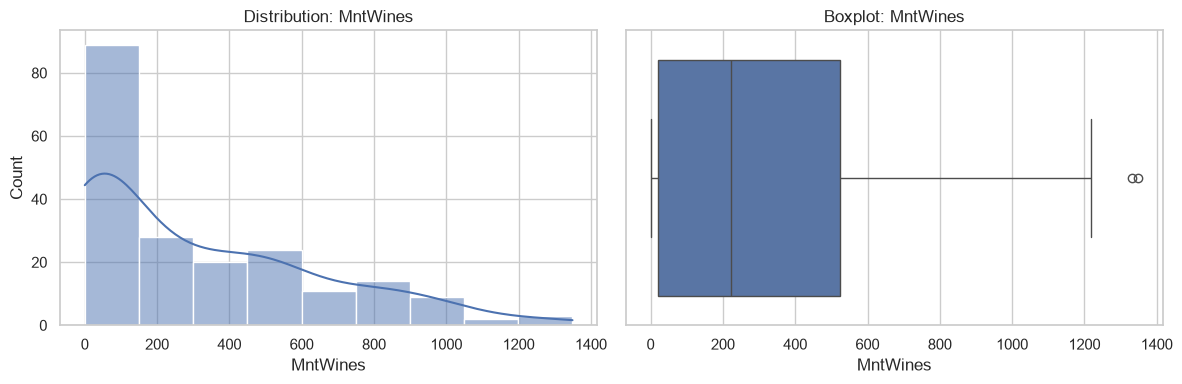

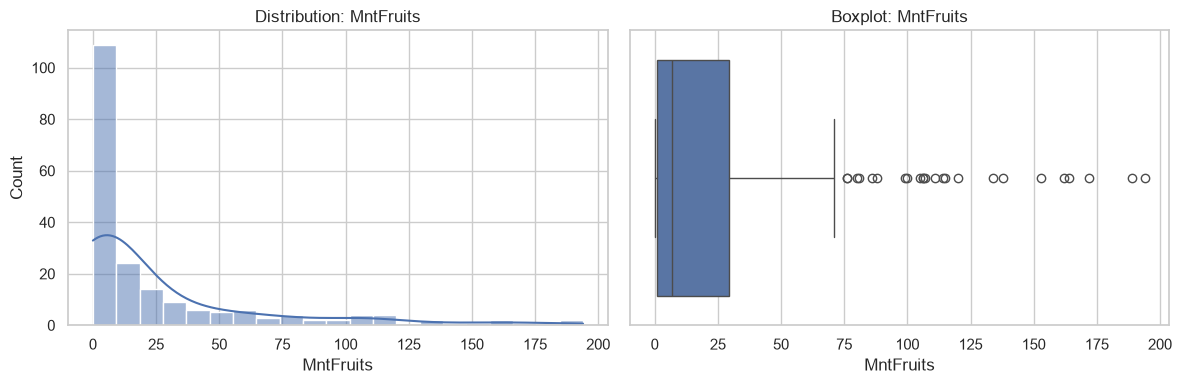

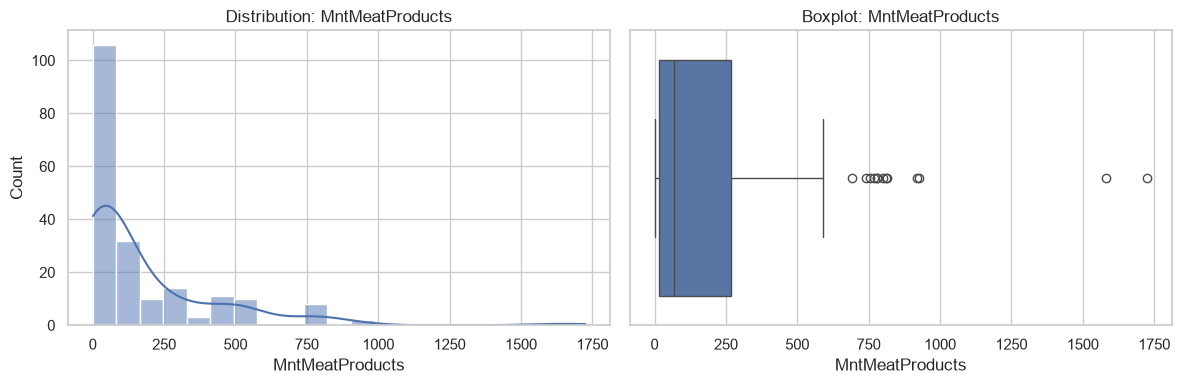

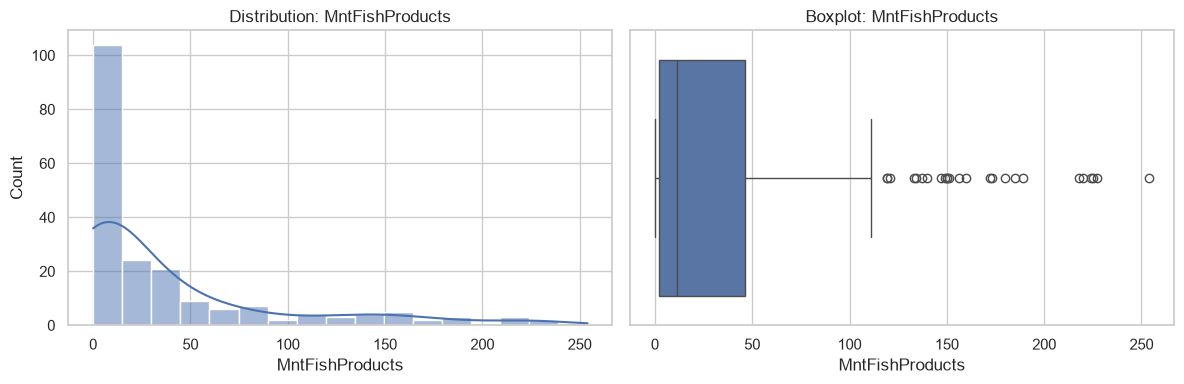

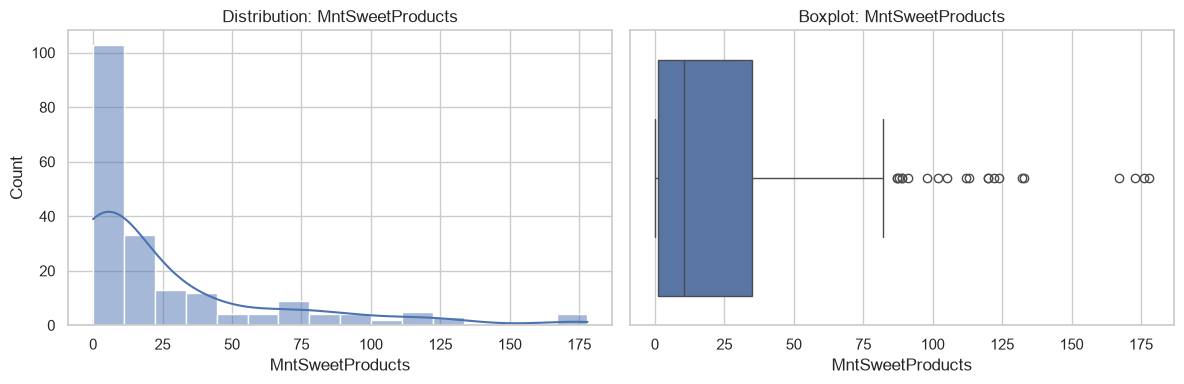

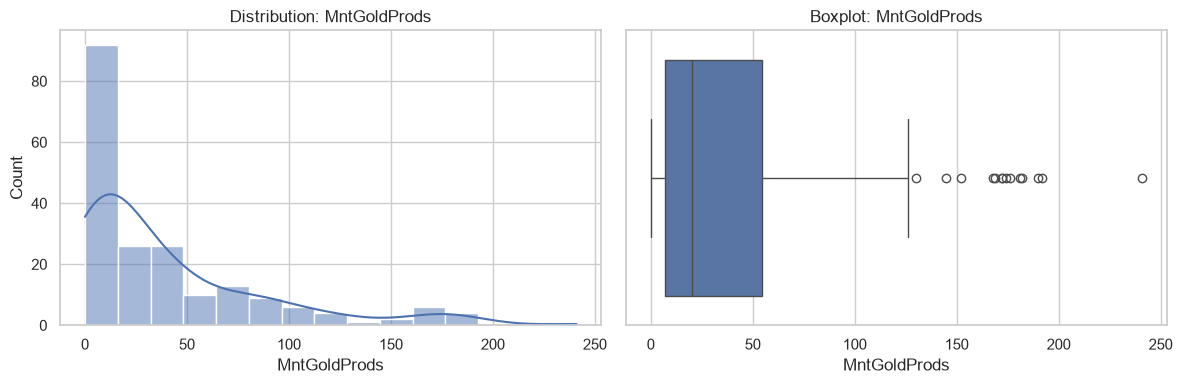

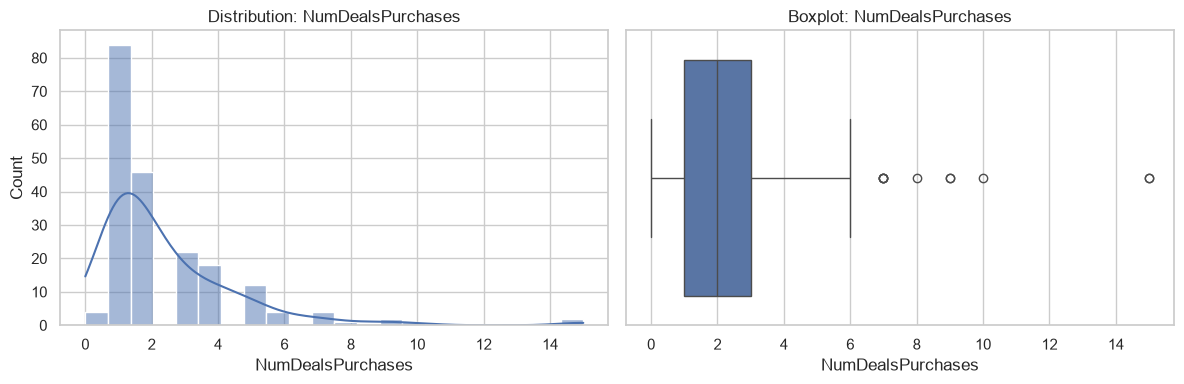

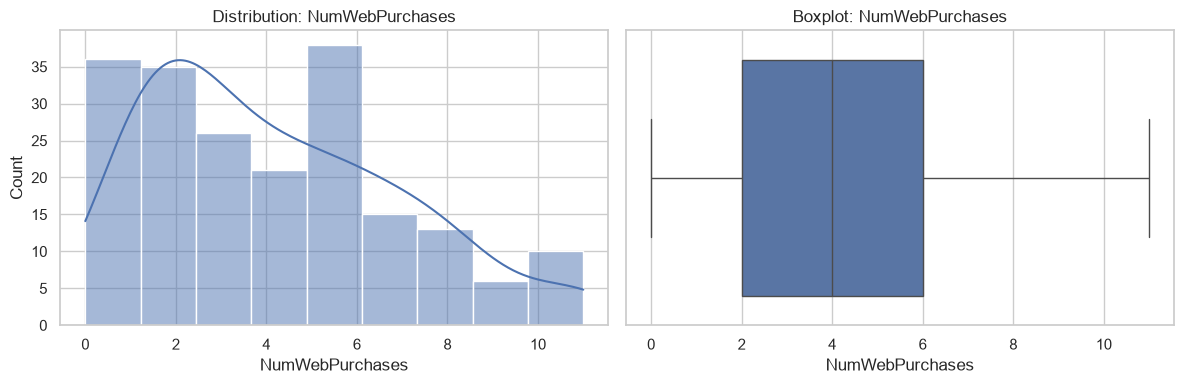

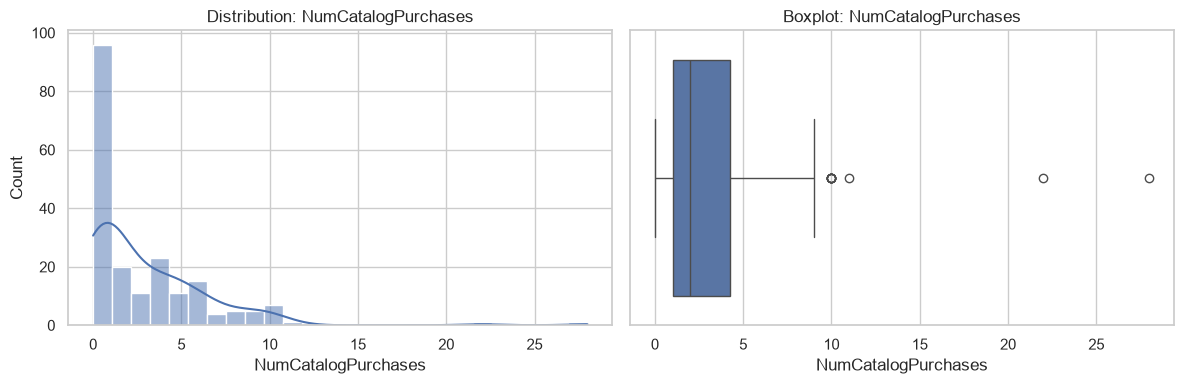

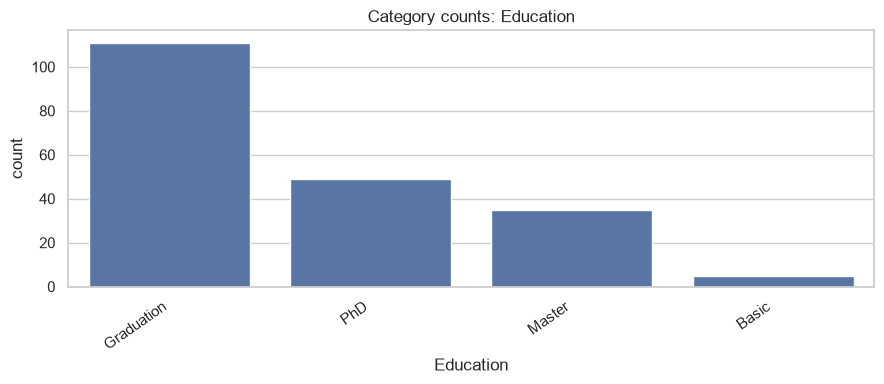

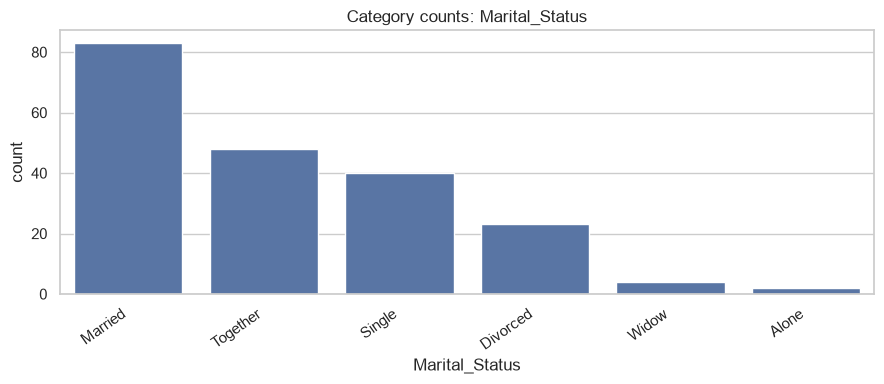

In [4]:
numeric_cols_eda = df.select_dtypes(include=np.number).columns.tolist()
cat_cols_eda = df.select_dtypes(exclude=np.number).columns.tolist()
print("Numerical columns:", numeric_cols_eda)
print("Categorical columns:", cat_cols_eda)

for col in numeric_cols_eda[:15]:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df[col], kde=True, ax=ax[0])
    ax[0].set_title(f"Distribution: {col}")
    sns.boxplot(x=df[col], ax=ax[1])
    ax[1].set_title(f"Boxplot: {col}")
    plt.tight_layout()
    plt.show()
for col in cat_cols_eda:
    if df[col].nunique(dropna=False) <= 15:
        plt.figure(figsize=(9, 4))
        sns.countplot(data=df, x=col, order=df[col].value_counts(dropna=False).index)
        plt.title(f"Category counts: {col}")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()


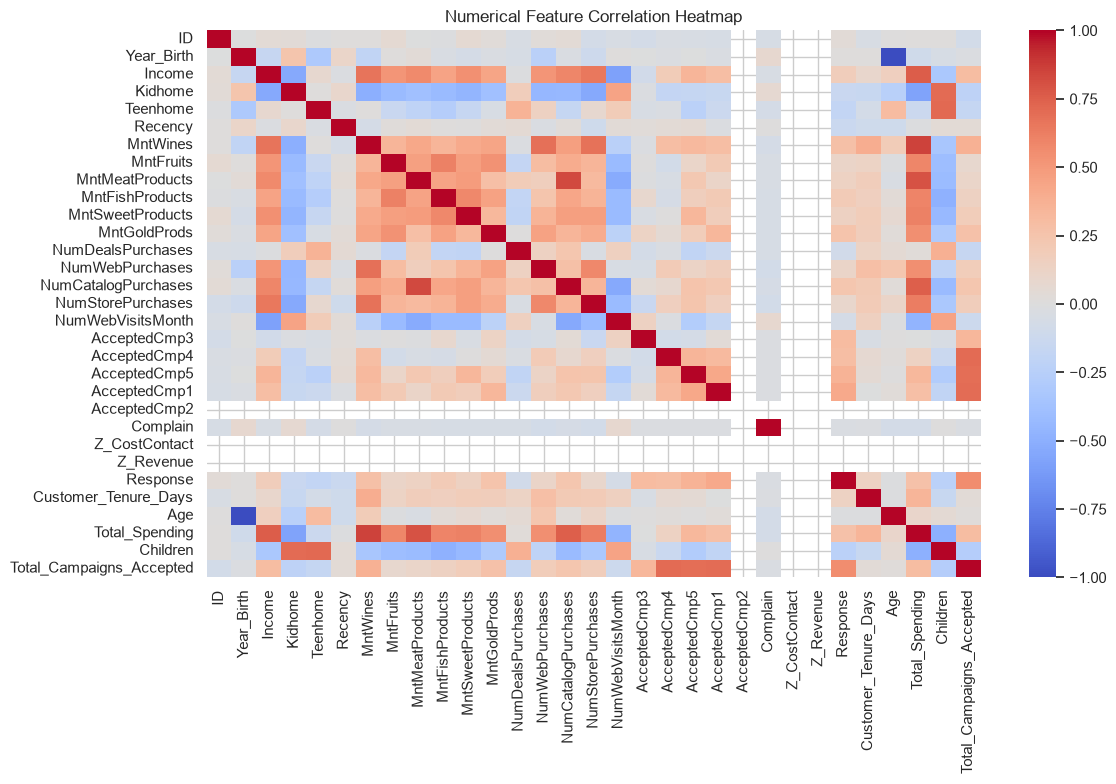

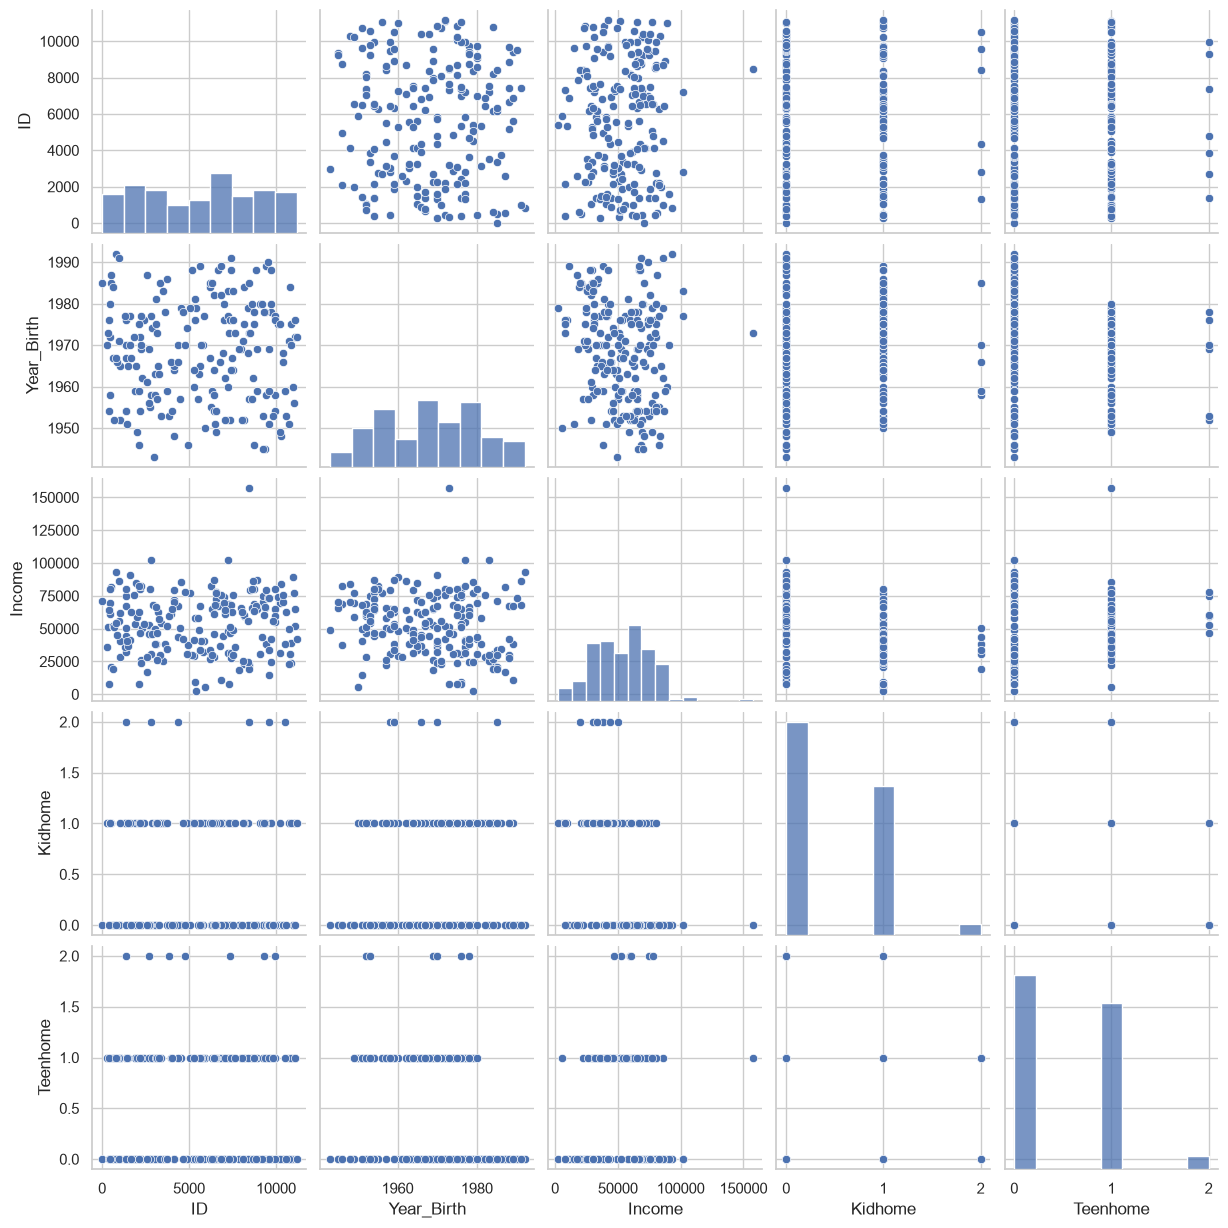

In [5]:
if len(numeric_cols_eda) >= 2:
    plt.figure(figsize=(12, 8))
    sns.heatmap(df[numeric_cols_eda].corr(), cmap="coolwarm", center=0)
    plt.title("Numerical Feature Correlation Heatmap")
    plt.tight_layout()
    plt.show()
    pair_cols = numeric_cols_eda[:5]
    if len(pair_cols) >= 2:
        sns.pairplot(df[pair_cols].dropna().sample(min(len(df), 700), random_state=SEED))
        plt.show()


In [6]:
# Exclude identifiers and response/target-like campaign outcomes to focus on customer profiles.
exclude_names = set(id_cols + ["Response", "Complain", "Z_CostContact", "Z_Revenue"])
model_df = df.drop(columns=[c for c in exclude_names if c in df.columns], errors="ignore").copy()
# Exclude raw birth year if a cleaned Age feature was created.
if "Age" in model_df.columns and "Year_Birth" in model_df.columns:
    model_df = model_df.drop(columns=["Year_Birth"])
# Remove columns that are entirely missing or constant.
model_df = model_df.dropna(axis=1, how="all")
model_df = model_df.loc[:, model_df.nunique(dropna=False) > 1]
num_features = model_df.select_dtypes(include=np.number).columns.tolist()
cat_features = model_df.select_dtypes(exclude=np.number).columns.tolist()
print("Modeling numerical features:", num_features)
print("Modeling categorical features:", cat_features)

try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
transformers = []
if num_features:
    transformers.append(("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_features))
if cat_features:
    transformers.append(("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", ohe)]), cat_features))
if not transformers:
    raise ValueError("No usable features remain after cleaning.")
preprocessor = ColumnTransformer(transformers, remainder="drop")
X = np.asarray(preprocessor.fit_transform(model_df), dtype=float)
if not np.isfinite(X).all():
    raise ValueError("Preprocessed data contains non-finite values. Inspect missing or infinite values.")
print("Processed matrix:", X.shape)


Modeling numerical features: ['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'Customer_Tenure_Days', 'Age', 'Total_Spending', 'Children', 'Total_Campaigns_Accepted']
Modeling categorical features: ['Education', 'Marital_Status']
Processed matrix: (200, 34)


PCA explained variance: [0.306  0.0973]
Total variance in 2 components: 0.4033


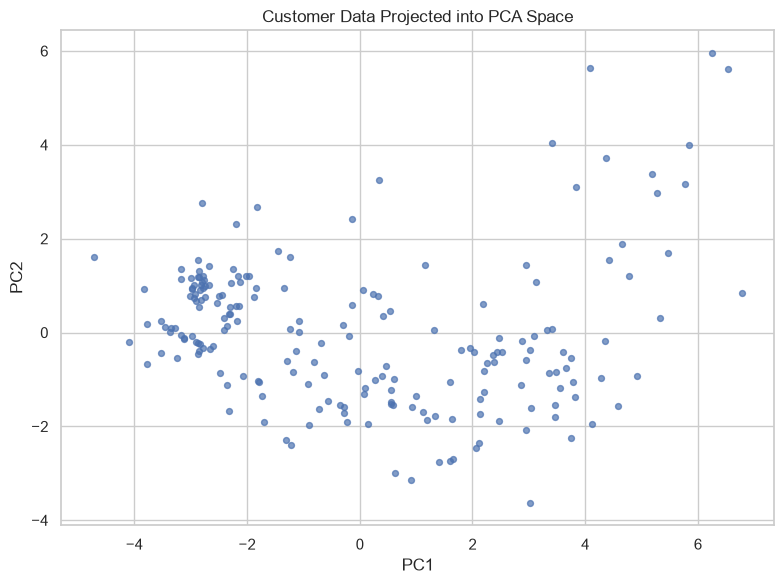

In [7]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X)
print("PCA explained variance:", np.round(pca.explained_variance_ratio_, 4))
print("Total variance in 2 components:", round(pca.explained_variance_ratio_.sum(), 4))
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=18, alpha=0.7)
plt.title("Customer Data Projected into PCA Space")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()


In [8]:
def evaluate_labels(X_eval, labels, noise_label=None):
    labels = np.asarray(labels)
    keep = np.ones(len(labels), dtype=bool)
    if noise_label is not None:
        keep = labels != noise_label
    x_use = X_eval[keep]
    y_use = labels[keep]
    unique = np.unique(y_use)
    n_clusters = len(unique)
    if n_clusters < 2 or n_clusters >= len(y_use):
        return {"Silhouette": np.nan, "Calinski-Harabasz": np.nan, "Davies-Bouldin": np.nan}
    return {
        "Silhouette": float(silhouette_score(x_use, y_use)),
        "Calinski-Harabasz": float(calinski_harabasz_score(x_use, y_use)),
        "Davies-Bouldin": float(davies_bouldin_score(x_use, y_use))
    }

def plot_clusters_2d(labels, title, noise_label=None):
    plt.figure(figsize=(9, 6))
    sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", s=24, alpha=0.8)
    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.colorbar(sc, label="Cluster label")
    plt.tight_layout()
    plt.show()

def show_cluster_profile(labels, title):
    temp = df.copy()
    temp["Cluster"] = np.asarray(labels)
    profile_cols = [c for c in ["Income", "Age", "Total_Spending", "Spent", "Recency", "Children", "Customer_Tenure_Days", "Total_Campaigns_Accepted"] if c in temp.columns]
    if profile_cols:
        display(temp.groupby("Cluster")[profile_cols].mean(numeric_only=True).round(2))
        for col in profile_cols[:6]:
            plt.figure(figsize=(8, 4))
            sns.boxplot(data=temp, x="Cluster", y=col)
            plt.title(f"{col} by {title} cluster")
            plt.tight_layout()
            plt.show()
    display(temp["Cluster"].value_counts().sort_index().rename("Count").to_frame())


,K,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,3860.845826,0.254255,61.673446,1.706262
1,3,3452.604912,0.172580,45.955525,2.008039
2,4,3125.783368,0.189137,40.499580,1.913485
3,5,2976.723137,0.126857,34.174142,2.032214
4,6,2750.072929,0.136363,32.638500,1.763538
5,7,2728.653310,0.123726,27.523461,2.178517
6,8,2499.145081,0.146102,28.143493,1.733930
7,9,2421.673271,0.136050,26.044778,1.937159
8,10,2319.382896,0.135593,24.976421,1.757524


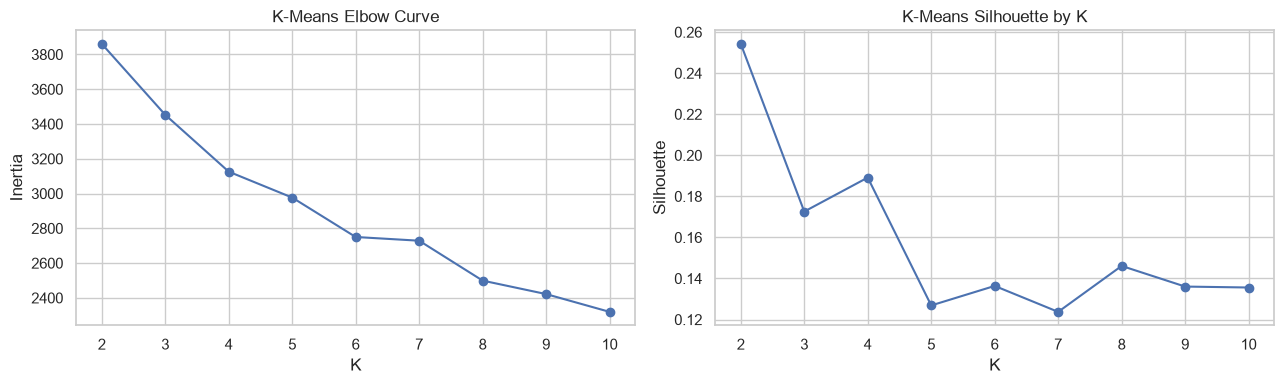

Selected K-Means K: 2


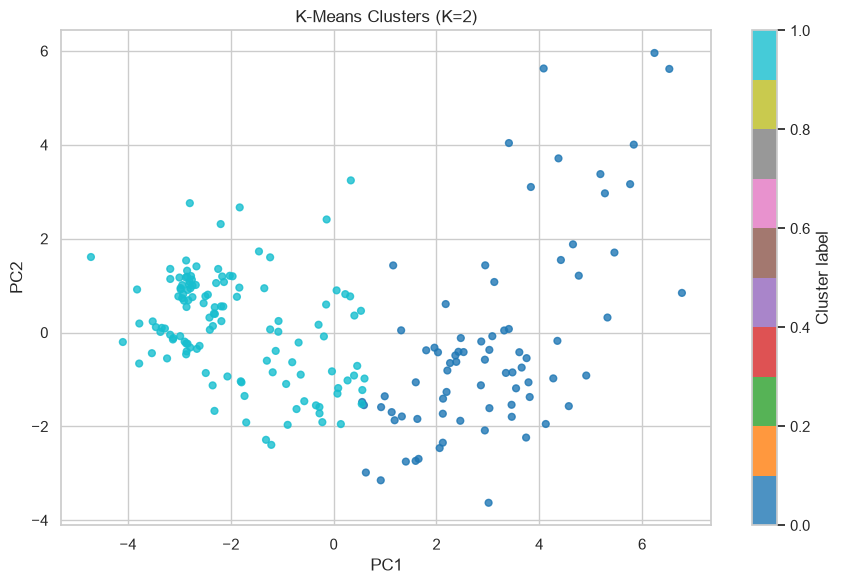

,Income,Age,Total_Spending,Recency,Children,Customer_Tenure_Days,Total_Campaigns_Accepted
Cluster,,,,,,,
0,73560.68,59.26,1287.92,47.03,0.42,422.78,0.45
1,40787.86,56.79,228.17,46.76,1.33,310.40,0.15


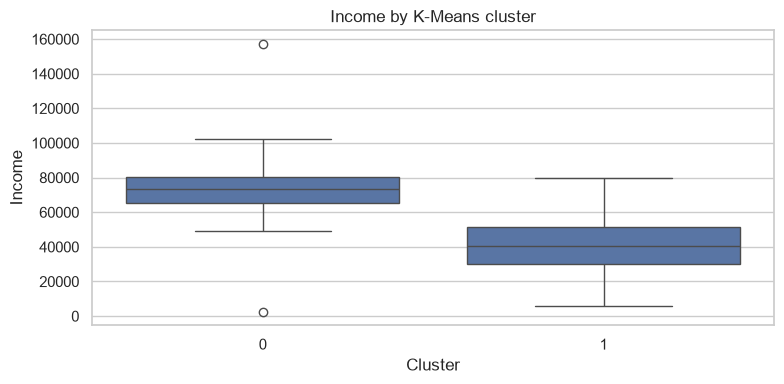

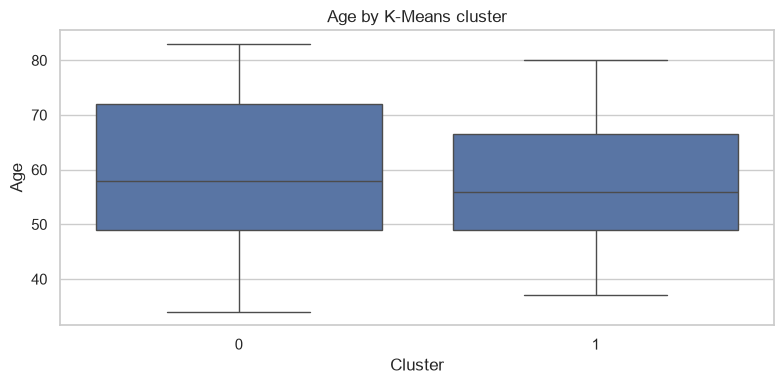

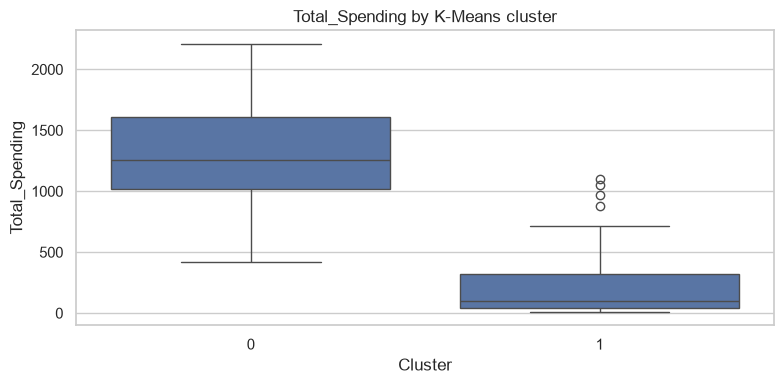

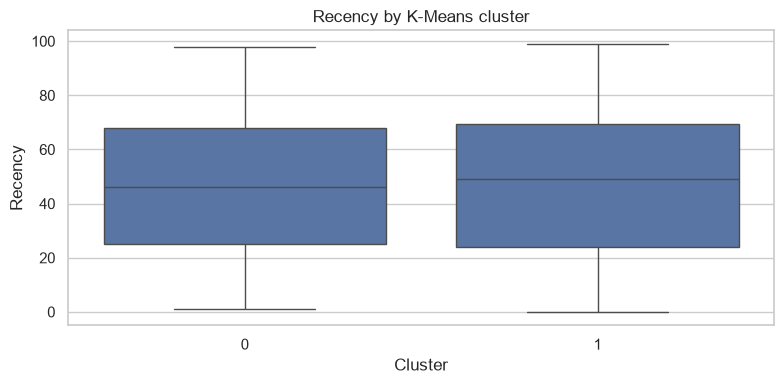

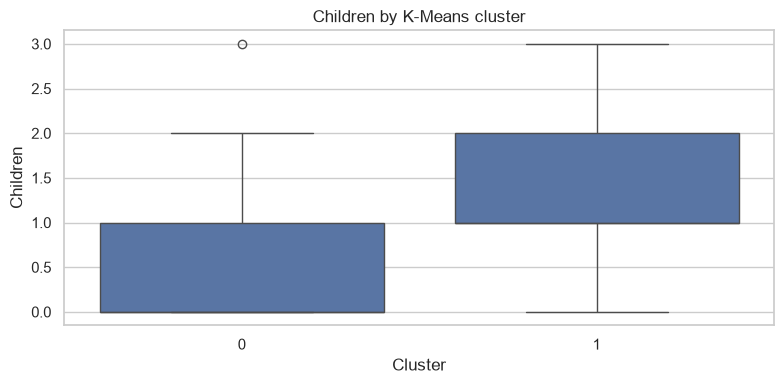

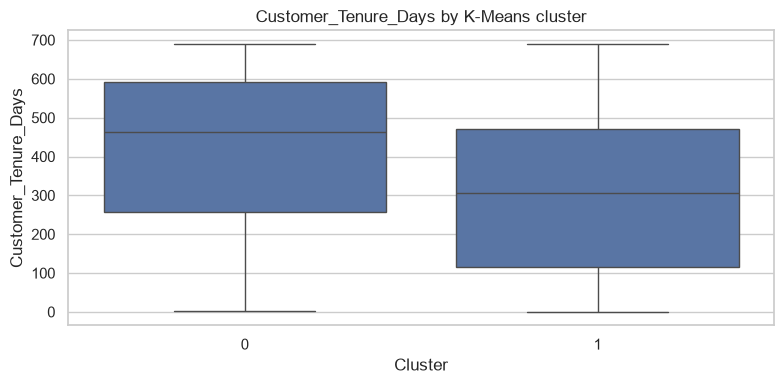

,Count
Cluster,
0,77
1,123


In [9]:
k_values = range(2, min(11, len(X)))
kmeans_rows = []
kmeans_models = {}
for k in k_values:
    model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = model.fit_predict(X)
    scores = evaluate_labels(X, labels)
    kmeans_models[k] = (model, labels)
    kmeans_rows.append({"K": k, "Inertia": model.inertia_, **scores})
kmeans_results = pd.DataFrame(kmeans_rows)
display(kmeans_results)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(kmeans_results["K"], kmeans_results["Inertia"], marker="o")
ax[0].set_title("K-Means Elbow Curve")
ax[0].set_xlabel("K")
ax[0].set_ylabel("Inertia")
ax[1].plot(kmeans_results["K"], kmeans_results["Silhouette"], marker="o")
ax[1].set_title("K-Means Silhouette by K")
ax[1].set_xlabel("K")
ax[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()
kmeans_valid = kmeans_results.dropna(subset=["Silhouette"])
if kmeans_valid.empty:
    raise ValueError("Could not evaluate K-Means cluster counts.")
best_k = int(kmeans_valid.loc[kmeans_valid["Silhouette"].idxmax(), "K"])
kmeans_model, labels_kmeans = kmeans_models[best_k]
print("Selected K-Means K:", best_k)
plot_clusters_2d(labels_kmeans, f"K-Means Clusters (K={best_k})")
show_cluster_profile(labels_kmeans, "K-Means")


,K,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0.214337,56.048844,1.743951
1,3,0.149382,42.229510,2.122543
2,4,0.167868,37.134316,2.003930
3,5,0.176003,33.353399,1.710189
4,6,0.116787,30.481021,1.835945
5,7,0.122502,28.459960,1.798122
6,8,0.136113,27.179273,1.692126
7,9,0.141103,26.068619,1.699556
8,10,0.146602,24.766695,1.656123


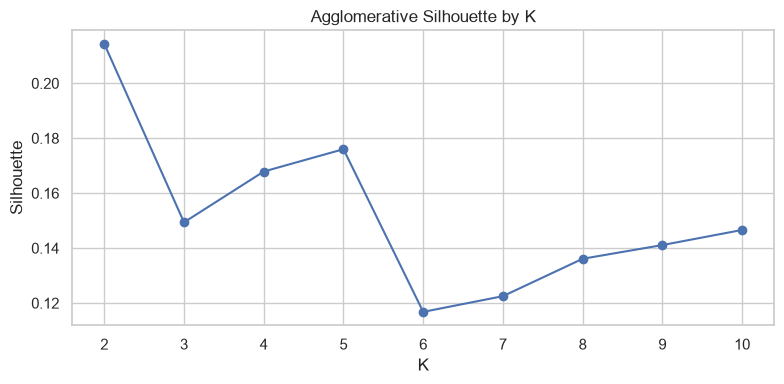

Selected Agglomerative K: 2


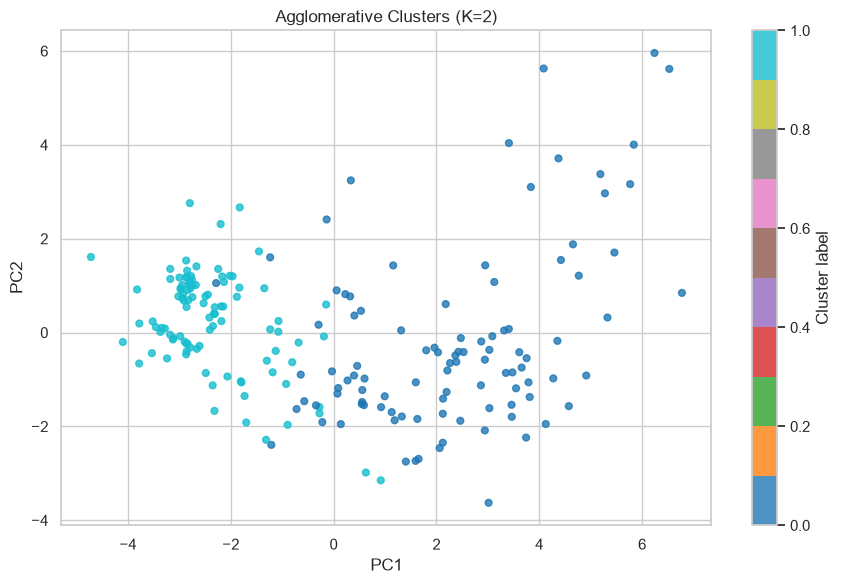

,Income,Age,Total_Spending,Recency,Children,Customer_Tenure_Days,Total_Campaigns_Accepted
Cluster,,,,,,,
0,69732.47,60.44,1102.24,45.32,0.58,390.39,0.46
1,36748.48,54.99,160.70,48.43,1.37,316.20,0.07


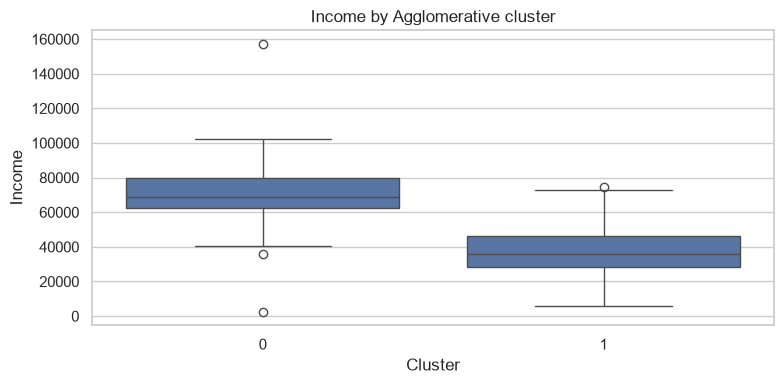

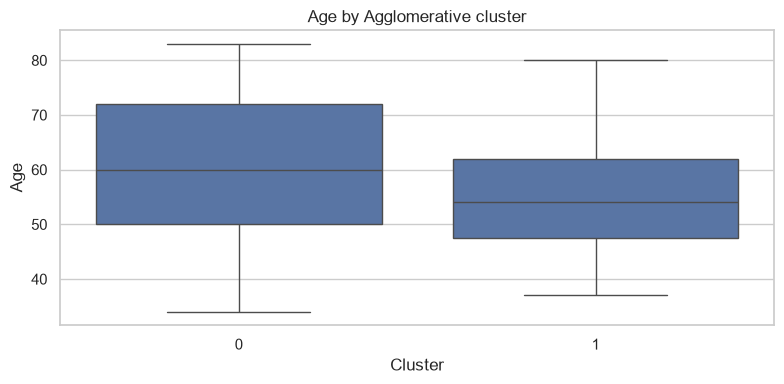

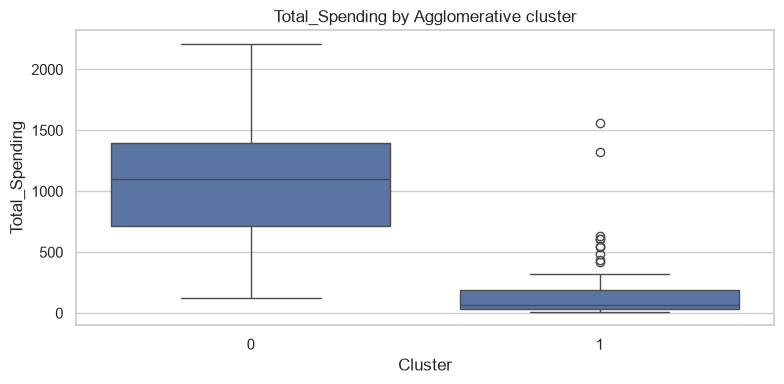

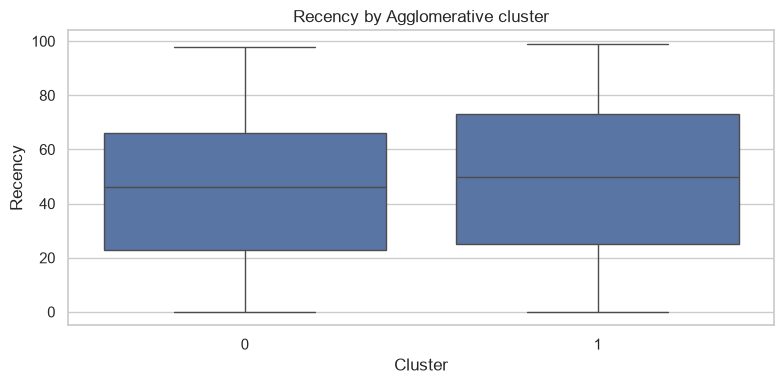

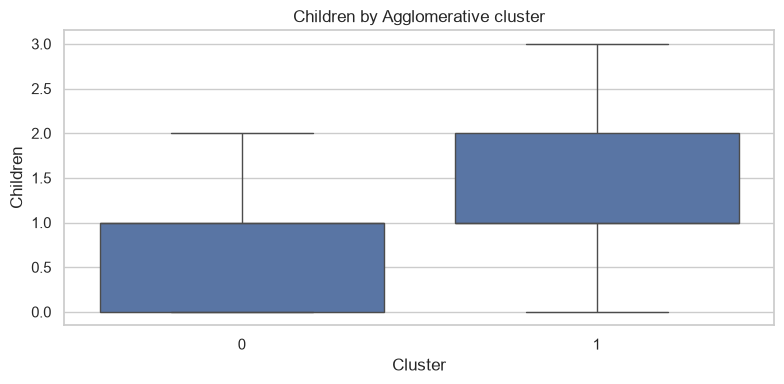

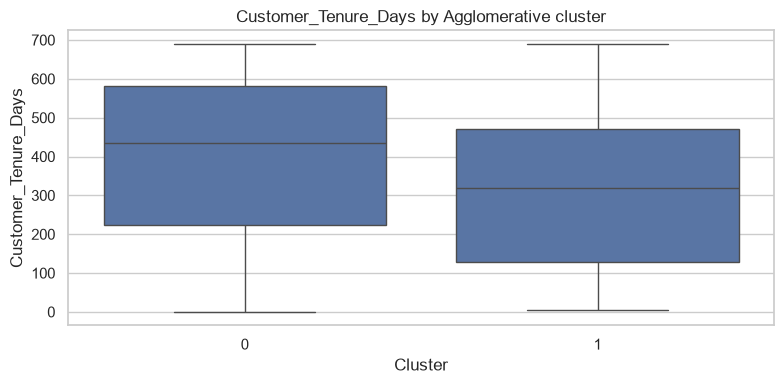

,Count
Cluster,
0,101
1,99


In [10]:
hier_rows = []
hier_models = {}
for k in range(2, min(11, len(X))):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X)
    hier_models[k] = (model, labels)
    hier_rows.append({"K": k, **evaluate_labels(X, labels)})
hier_results = pd.DataFrame(hier_rows)
display(hier_results)
plt.figure(figsize=(8, 4))
plt.plot(hier_results["K"], hier_results["Silhouette"], marker="o")
plt.title("Agglomerative Silhouette by K")
plt.xlabel("K")
plt.ylabel("Silhouette")
plt.tight_layout()
plt.show()
hier_valid = hier_results.dropna(subset=["Silhouette"])
best_hier_k = int(hier_valid.loc[hier_valid["Silhouette"].idxmax(), "K"])
hier_model, labels_hier = hier_models[best_hier_k]
print("Selected Agglomerative K:", best_hier_k)
plot_clusters_2d(labels_hier, f"Agglomerative Clusters (K={best_hier_k})")
show_cluster_profile(labels_hier, "Agglomerative")


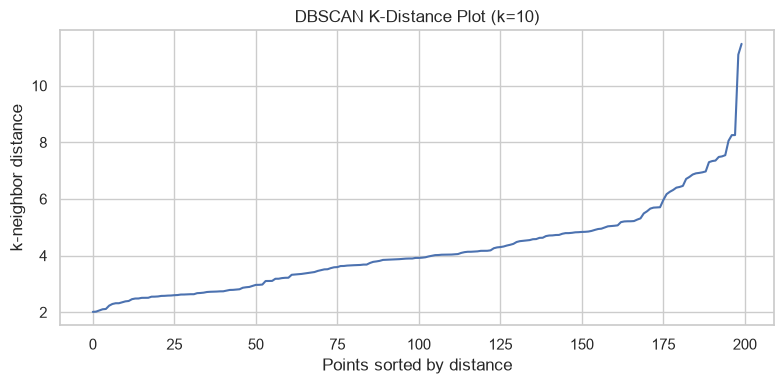

,eps,min_samples,Clusters,Noise_Points,Noise_Rate,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,3.917815,8,1,63,0.315,NaN,NaN,NaN
1,3.917815,10,1,64,0.320,NaN,NaN,NaN
2,3.917815,15,1,78,0.390,NaN,NaN,NaN
3,4.167581,8,1,55,0.275,NaN,NaN,NaN
4,4.167581,10,1,57,0.285,NaN,NaN,NaN
5,4.167581,15,1,67,0.335,NaN,NaN,NaN
6,4.694568,8,1,33,0.165,NaN,NaN,NaN
7,4.694568,10,1,33,0.165,NaN,NaN,NaN
8,4.694568,15,1,35,0.175,NaN,NaN,NaN
9,5.044786,8,1,24,0.120,NaN,NaN,NaN


Selected DBSCAN eps/min_samples: (6.401431472799867, 10)
Detected clusters: 1 | Noise points: 9


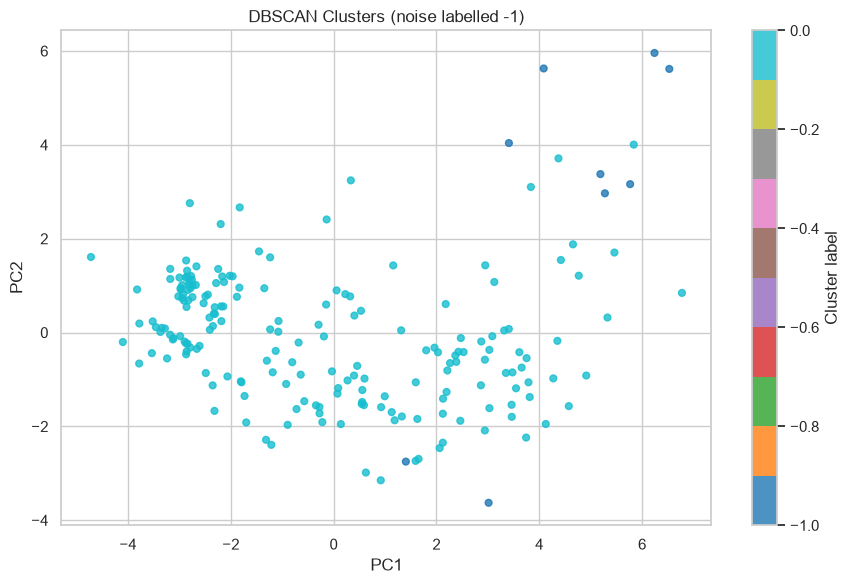

,Income,Age,Total_Spending,Recency,Children,Customer_Tenure_Days,Total_Campaigns_Accepted
Cluster,,,,,,,
-1,86578.89,54.22,1375.89,61.56,0.33,427.67,1.89
0,51842.25,57.91,601.32,46.17,1.01,350.18,0.19


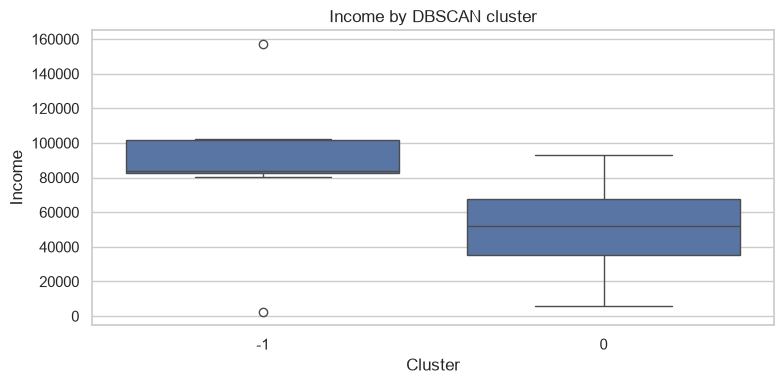

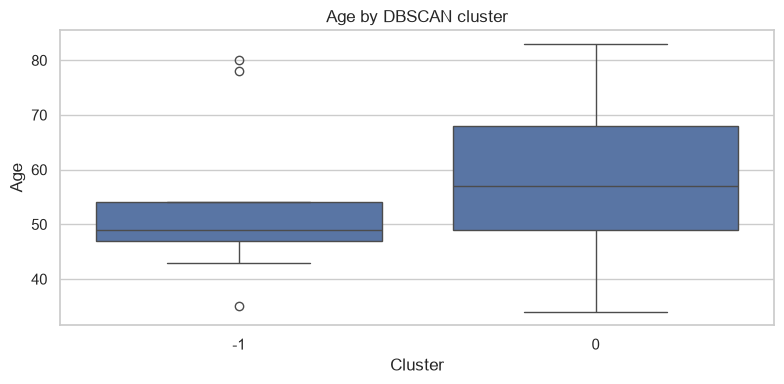

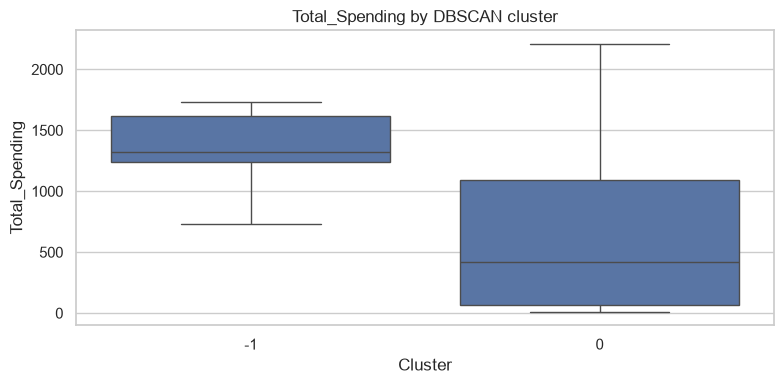

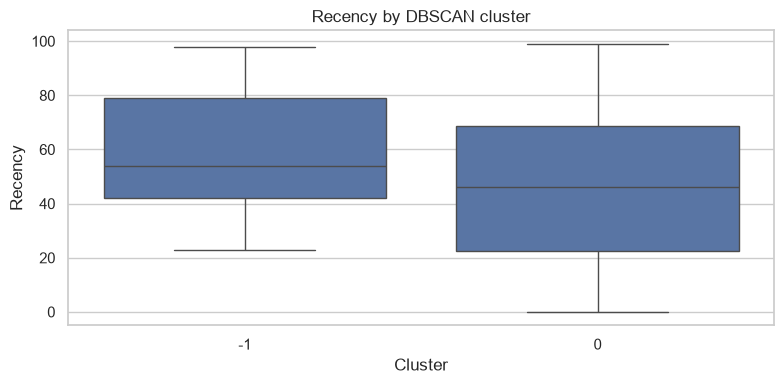

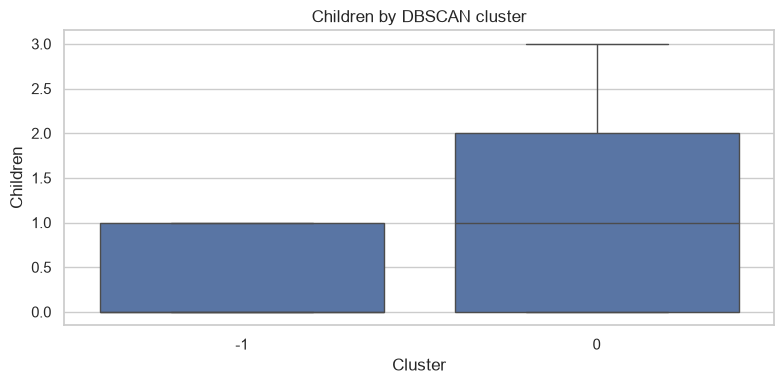

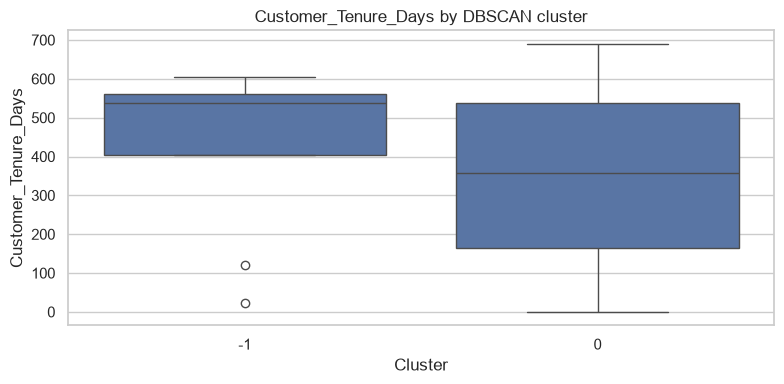

,Count
Cluster,
-1,9
0,191


In [11]:
# Use a k-distance plot to help interpret candidate eps values.
min_samples_db = max(5, min(10, X.shape[1] + 1))
n_neighbors = min(min_samples_db, len(X))
neighbor_model = NearestNeighbors(n_neighbors=n_neighbors).fit(X)
distances, _ = neighbor_model.kneighbors(X)
k_distances = np.sort(distances[:, -1])
plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.title(f"DBSCAN K-Distance Plot (k={n_neighbors})")
plt.xlabel("Points sorted by distance")
plt.ylabel("k-neighbor distance")
plt.tight_layout()
plt.show()

# Search candidate eps values from the observed k-distance distribution.
eps_candidates = np.unique(np.quantile(k_distances, [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.98]))
min_samples_candidates = sorted(set([max(3, min_samples_db - 2), min_samples_db, min(min_samples_db + 5, len(X))]))
dbscan_rows = []
dbscan_models = {}
for eps in eps_candidates:
    if eps <= 0:
        continue
    for ms in min_samples_candidates:
        model = DBSCAN(eps=float(eps), min_samples=int(ms))
        labels = model.fit_predict(X)
        n_clusters = len(set(labels) - {-1})
        n_noise = int(np.sum(labels == -1))
        scores = evaluate_labels(X, labels, noise_label=-1)
        row = {"eps": float(eps), "min_samples": int(ms), "Clusters": n_clusters, "Noise_Points": n_noise, "Noise_Rate": n_noise / len(labels), **scores}
        dbscan_rows.append(row)
        dbscan_models[(float(eps), int(ms))] = (model, labels)
dbscan_results = pd.DataFrame(dbscan_rows)
display(dbscan_results.sort_values("Silhouette", ascending=False, na_position="last").head(15))
db_valid = dbscan_results.dropna(subset=["Silhouette"])
if not db_valid.empty:
    best_db_row = db_valid.sort_values(["Silhouette", "Noise_Rate"], ascending=[False, True]).iloc[0]
    best_db_key = (float(best_db_row["eps"]), int(best_db_row["min_samples"]))
else:
    # Sensible fallback when the candidate grid yields fewer than two non-noise clusters.
    fallback_eps = float(np.quantile(k_distances, 0.90))
    best_db_key = (max(fallback_eps, 1e-6), int(min_samples_db))
    dbscan_models[best_db_key] = (DBSCAN(eps=best_db_key[0], min_samples=best_db_key[1]), None)
    dbscan_models[best_db_key][0].fit(X)
    dbscan_models[best_db_key] = (dbscan_models[best_db_key][0], dbscan_models[best_db_key][0].labels_)
dbscan_model, labels_dbscan = dbscan_models[best_db_key]
print("Selected DBSCAN eps/min_samples:", best_db_key)
print("Detected clusters:", len(set(labels_dbscan) - {-1}), "| Noise points:", int(np.sum(labels_dbscan == -1)))
plot_clusters_2d(labels_dbscan, "DBSCAN Clusters (noise labelled -1)")
show_cluster_profile(labels_dbscan, "DBSCAN")


,K,Medoid_Cost,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,945.648370,0.253793,55.142259,1.748933
1,3,997.250375,0.222972,20.972418,1.761892
2,4,859.769036,0.175145,31.744401,2.822672
3,5,826.736507,0.137009,30.181661,1.811411
4,6,820.512974,0.138598,27.904790,1.666469
5,7,812.053381,0.123714,24.655982,1.828115


Selected K-Medoids K: 2
Medoid row indices: [ 46 152]


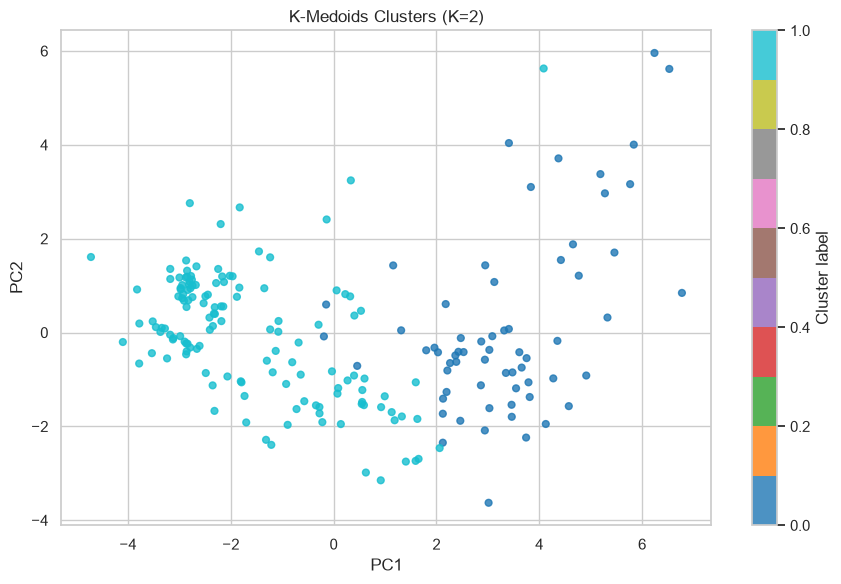

,Income,Age,Total_Spending,Recency,Children,Customer_Tenure_Days,Total_Campaigns_Accepted
Cluster,,,,,,,
0,75517.59,59.25,1298.44,46.42,0.20,405.30,0.50
1,42999.65,57.03,324.52,47.07,1.34,329.37,0.15


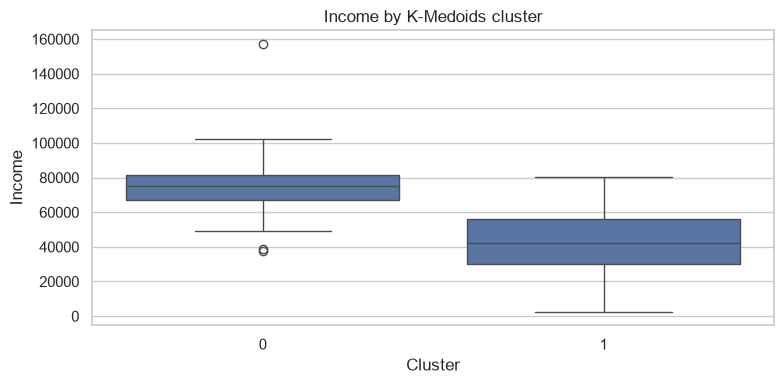

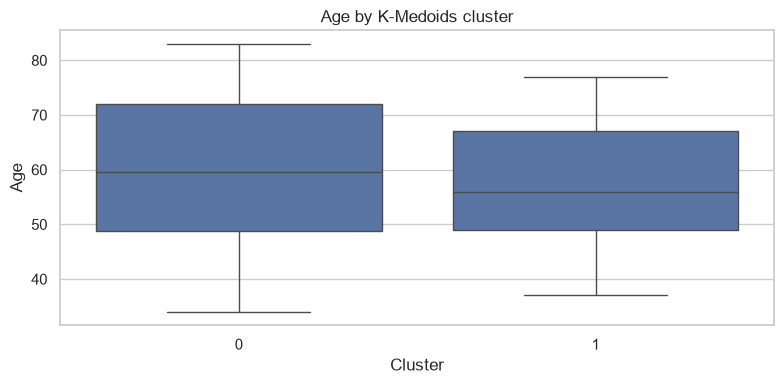

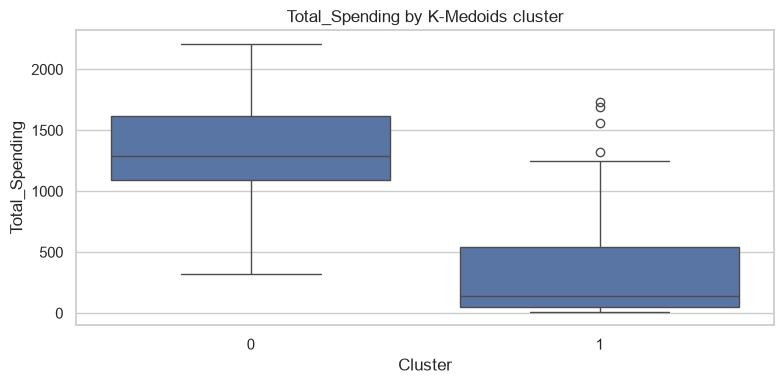

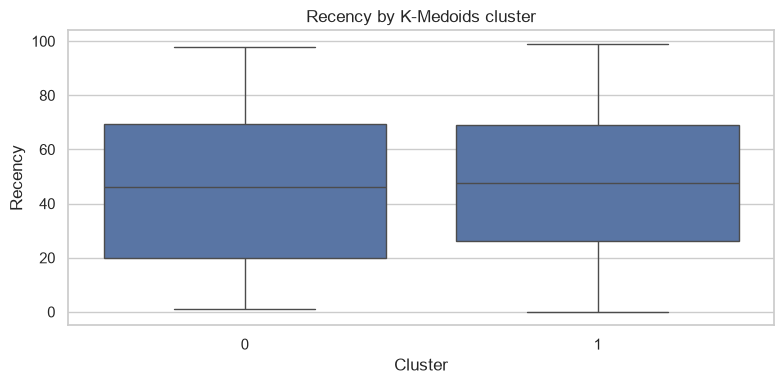

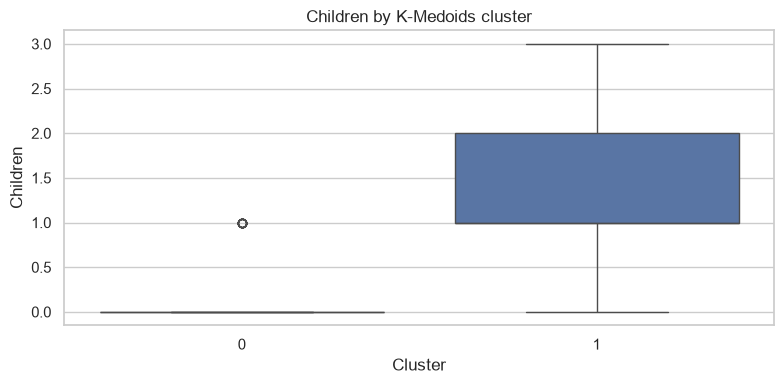

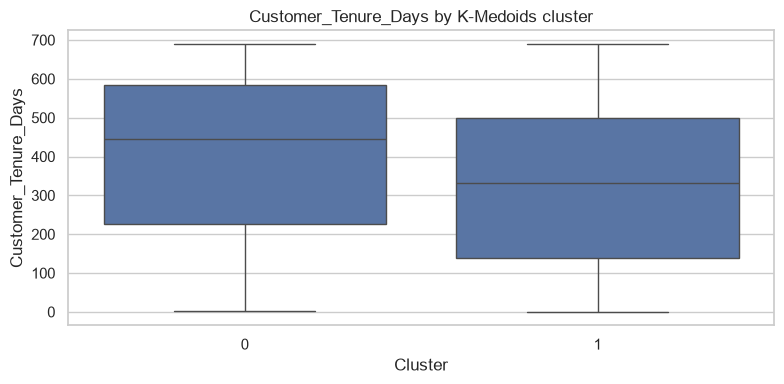

,Count
Cluster,
0,64
1,136


In [12]:
def kmedoids_fit(X, n_clusters, random_state=42, max_iter=100):
    """Simple K-Medoids using pairwise Euclidean distances and alternating medoid updates."""
    n = X.shape[0]
    if n_clusters < 2 or n_clusters >= n:
        raise ValueError("n_clusters must be between 2 and n_samples-1")
    D = pairwise_distances(X, metric="euclidean")
    rng = np.random.default_rng(random_state)
    medoids = rng.choice(n, size=n_clusters, replace=False)
    labels = None
    for _ in range(max_iter):
        new_labels = np.argmin(D[:, medoids], axis=1)
        new_medoids = medoids.copy()
        for cluster_id in range(n_clusters):
            members = np.where(new_labels == cluster_id)[0]
            if len(members) == 0:
                candidates = np.setdiff1d(np.arange(n), new_medoids)
                if len(candidates):
                    new_medoids[cluster_id] = rng.choice(candidates)
                continue
            within = D[np.ix_(members, members)]
            new_medoids[cluster_id] = members[np.argmin(within.sum(axis=1))]
        if np.array_equal(new_medoids, medoids):
            labels = new_labels
            medoids = new_medoids
            break
        medoids = new_medoids
        labels = new_labels
    labels = np.argmin(D[:, medoids], axis=1)
    return labels, medoids, D

# Pairwise distance matrix is O(n^2) memory; cap rows for very large datasets to keep runtime manageable.
if len(X) > 4000:
    raise ValueError("K-Medoids pairwise distances need O(n^2) memory. For this notebook, reduce the dataset to 4000 rows or fewer before running K-Medoids.")
medoid_rows = []
medoid_models = {}
for k in range(2, min(8, len(X))):
    labels, medoids, D = kmedoids_fit(X, k, random_state=SEED)
    scores = evaluate_labels(X, labels)
    cost = float(np.min(D[:, medoids], axis=1).sum())
    medoid_models[k] = (labels, medoids, D, cost)
    medoid_rows.append({"K": k, "Medoid_Cost": cost, **scores})
medoid_results = pd.DataFrame(medoid_rows)
display(medoid_results)
medoid_valid = medoid_results.dropna(subset=["Silhouette"])
best_medoid_k = int(medoid_valid.loc[medoid_valid["Silhouette"].idxmax(), "K"])
labels_kmedoids, medoid_indices, medoid_distances, medoid_cost = medoid_models[best_medoid_k]
print("Selected K-Medoids K:", best_medoid_k)
print("Medoid row indices:", medoid_indices)
plot_clusters_2d(labels_kmedoids, f"K-Medoids Clusters (K={best_medoid_k})")
show_cluster_profile(labels_kmedoids, "K-Medoids")


,K,Partition_Coefficient,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0.567177,0.237440,61.367676,1.700688
1,3,0.386534,0.139735,42.361438,2.161633
2,4,0.286546,0.093561,31.660721,2.722009
3,5,0.230805,0.073130,31.907096,2.521730
4,6,0.193267,0.081492,32.466006,2.260825
5,7,0.164211,0.077988,31.930863,2.650560


Selected Fuzzy C-Means K: 2
Partition coefficient (higher means crisper memberships): 0.5672


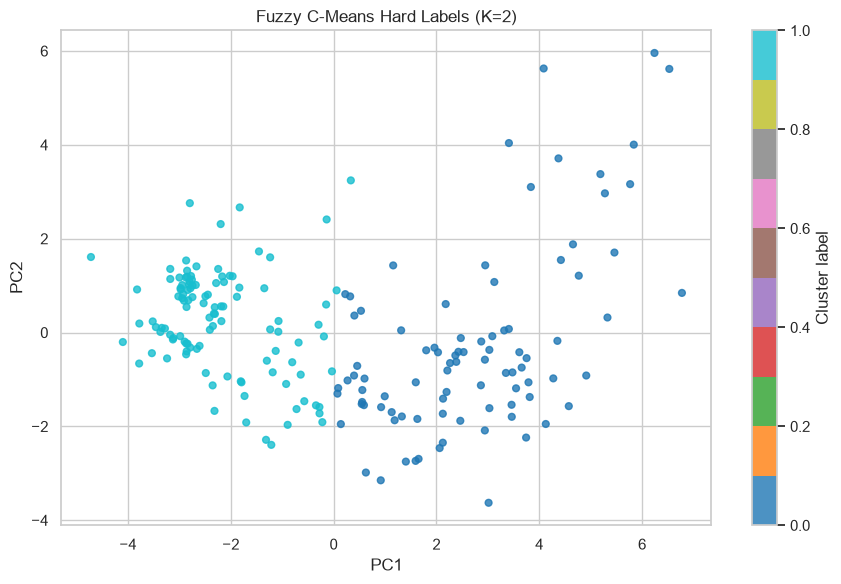

,Income,Age,Total_Spending,Recency,Children,Customer_Tenure_Days,Total_Campaigns_Accepted
Cluster,,,,,,,
0,72149.31,60.29,1203.86,44.29,0.51,400.63,0.43
1,38069.46,55.65,171.71,48.96,1.35,315.24,0.13


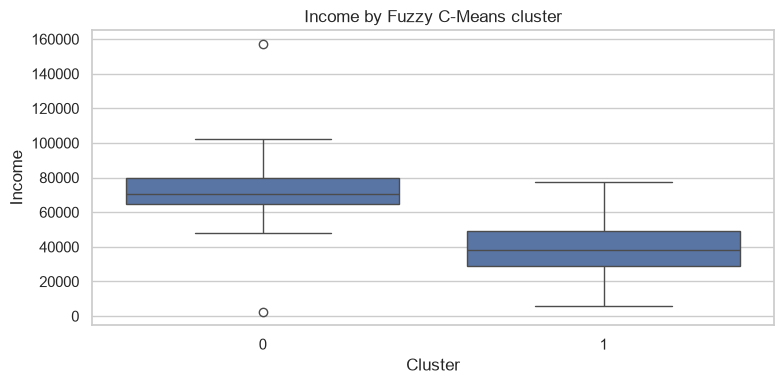

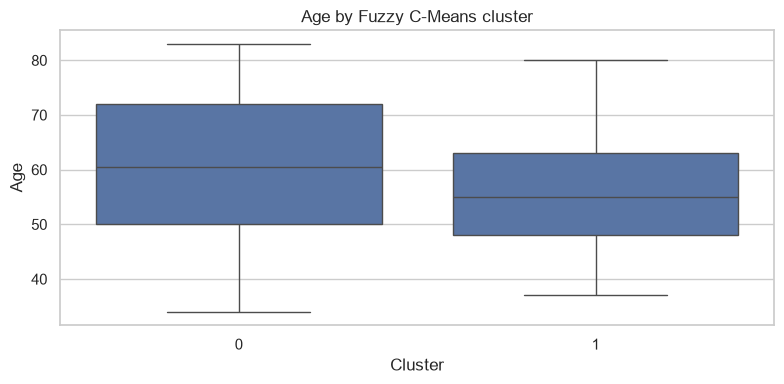

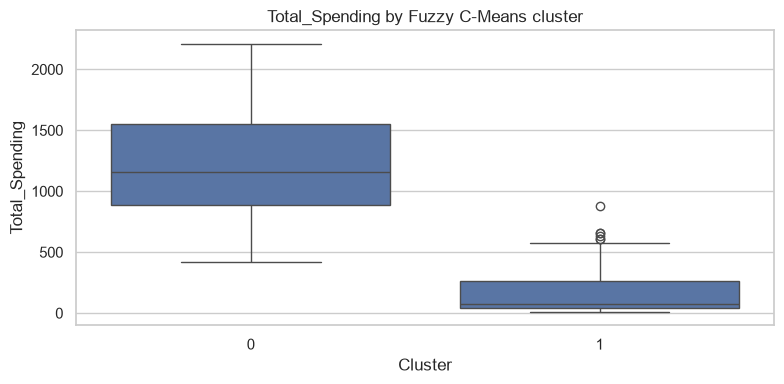

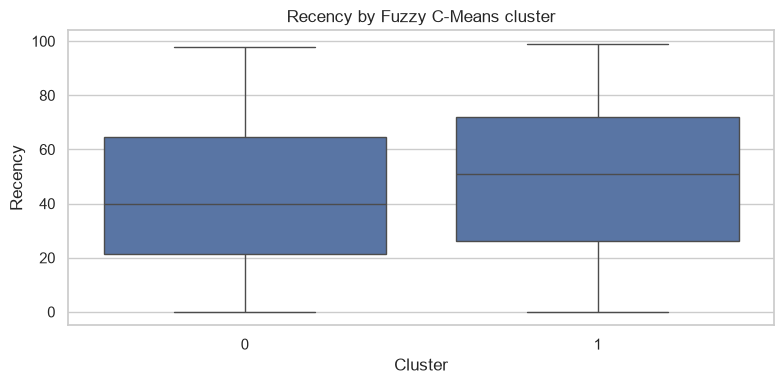

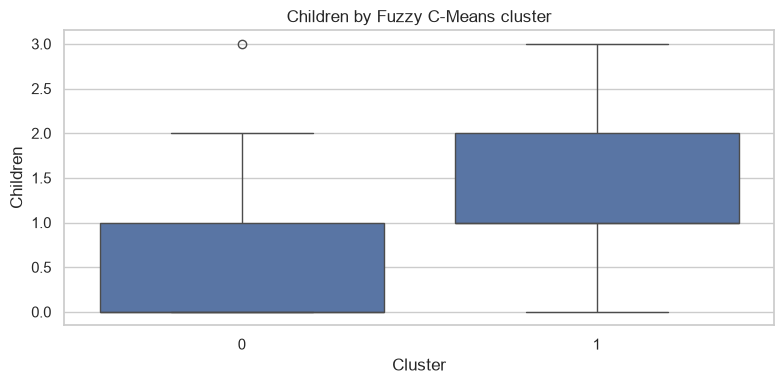

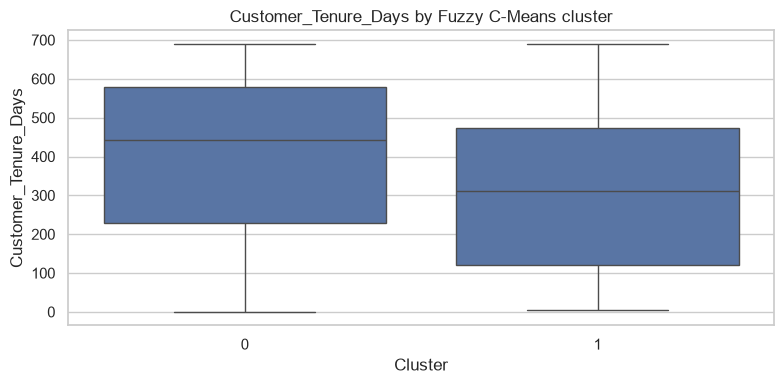

,Count
Cluster,
0,90
1,110


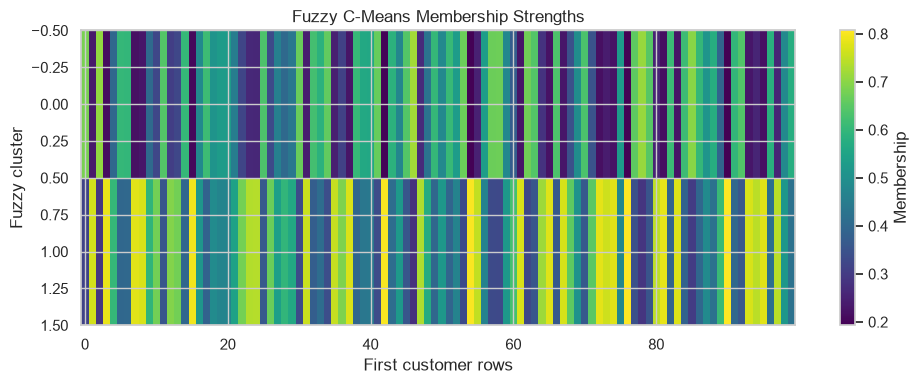

In [13]:
def fuzzy_c_means(X, n_clusters, m=2.0, max_iter=300, tol=1e-5, random_state=42):
    """Fuzzy C-Means implementation returning membership matrix and cluster centers."""
    if m <= 1:
        raise ValueError("Fuzzifier m must be greater than 1")
    n = X.shape[0]
    rng = np.random.default_rng(random_state)
    U = rng.random((n_clusters, n))
    U = U / U.sum(axis=0, keepdims=True)
    for _ in range(max_iter):
        U_old = U.copy()
        Um = U ** m
        centers = (Um @ X) / np.maximum(Um.sum(axis=1, keepdims=True), 1e-12)
        dist = pairwise_distances(centers, X, metric="euclidean")
        dist = np.maximum(dist, 1e-10)
        power = 2.0 / (m - 1.0)
        ratios = (dist[:, None, :] / dist[None, :, :]) ** power
        U = 1.0 / ratios.sum(axis=1)
        # Handle exact center matches robustly.
        zero_mask = dist <= 1e-10
        for j in range(n):
            zeros = np.where(zero_mask[:, j])[0]
            if len(zeros):
                U[:, j] = 0
                U[zeros, j] = 1 / len(zeros)
        if np.max(np.abs(U - U_old)) < tol:
            break
    labels = np.argmax(U, axis=0)
    return labels, U, centers

fcm_rows = []
fcm_models = {}
for k in range(2, min(8, len(X))):
    labels, memberships, centers = fuzzy_c_means(X, k, m=2.0, random_state=SEED)
    scores = evaluate_labels(X, labels)
    partition_coefficient = float(np.mean(np.sum(memberships ** 2, axis=0)))
    fcm_models[k] = (labels, memberships, centers, partition_coefficient)
    fcm_rows.append({"K": k, "Partition_Coefficient": partition_coefficient, **scores})
fcm_results = pd.DataFrame(fcm_rows)
display(fcm_results)
fcm_valid = fcm_results.dropna(subset=["Silhouette"])
best_fcm_k = int(fcm_valid.loc[fcm_valid["Silhouette"].idxmax(), "K"])
labels_fcm, memberships_fcm, centers_fcm, fcm_pc = fcm_models[best_fcm_k]
print("Selected Fuzzy C-Means K:", best_fcm_k)
print("Partition coefficient (higher means crisper memberships):", round(fcm_pc, 4))
plot_clusters_2d(labels_fcm, f"Fuzzy C-Means Hard Labels (K={best_fcm_k})")
show_cluster_profile(labels_fcm, "Fuzzy C-Means")
plt.figure(figsize=(10, 4))
plt.imshow(memberships_fcm[:, :min(100, len(X))], aspect="auto", cmap="viridis")
plt.colorbar(label="Membership")
plt.xlabel("First customer rows")
plt.ylabel("Fuzzy cluster")
plt.title("Fuzzy C-Means Membership Strengths")
plt.tight_layout()
plt.show()


,Algorithm,Clusters (excluding noise),Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,K-Means,2,0,0.254255,61.673446,1.706262
3,K-Medoids,2,0,0.253793,55.142259,1.748933
4,Fuzzy C-Means,2,0,0.237440,61.367676,1.700688
1,Agglomerative,2,0,0.214337,56.048844,1.743951
2,DBSCAN,1,9,NaN,NaN,NaN


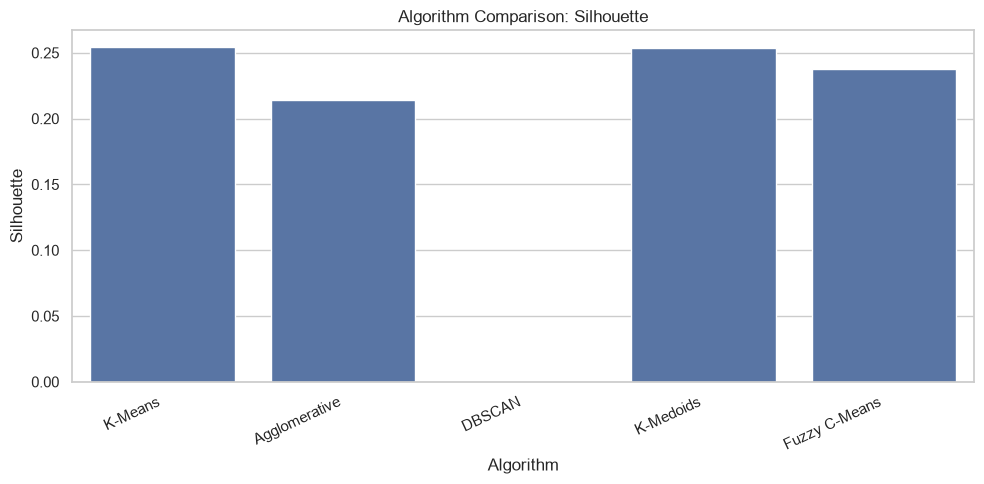

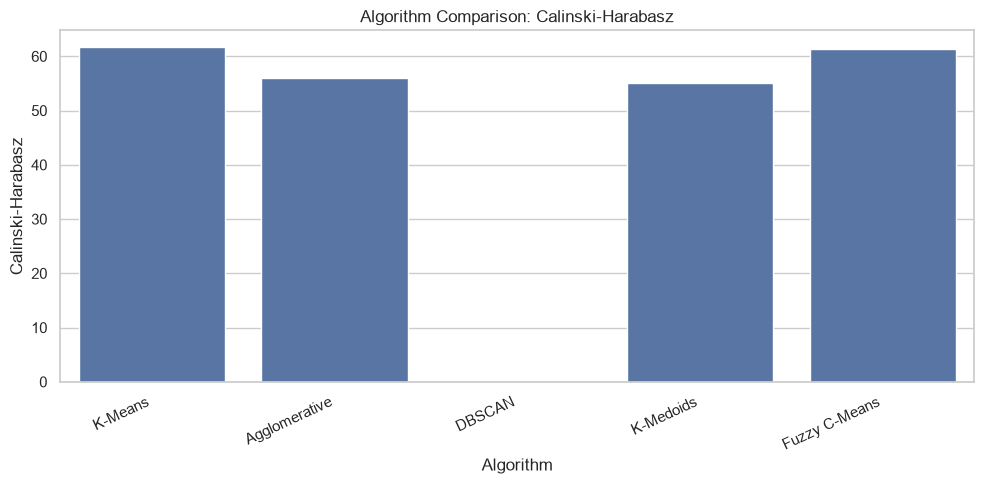

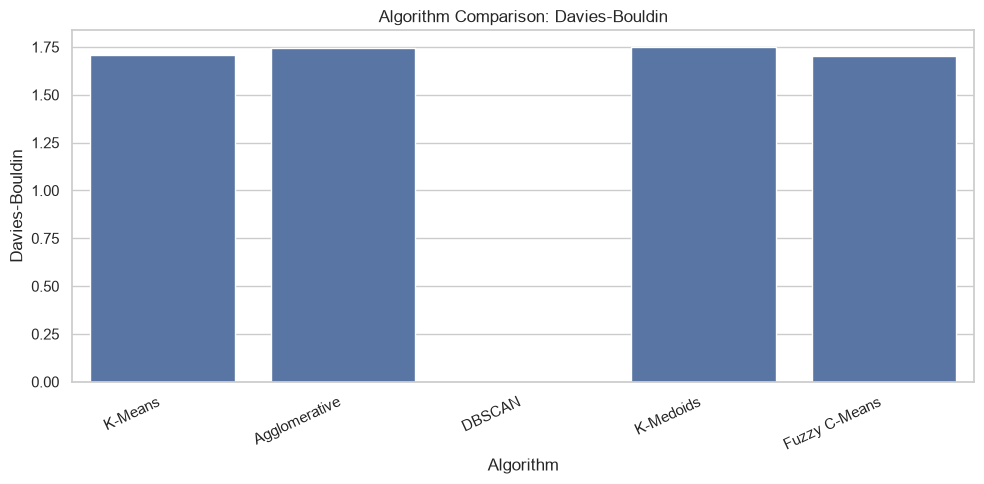

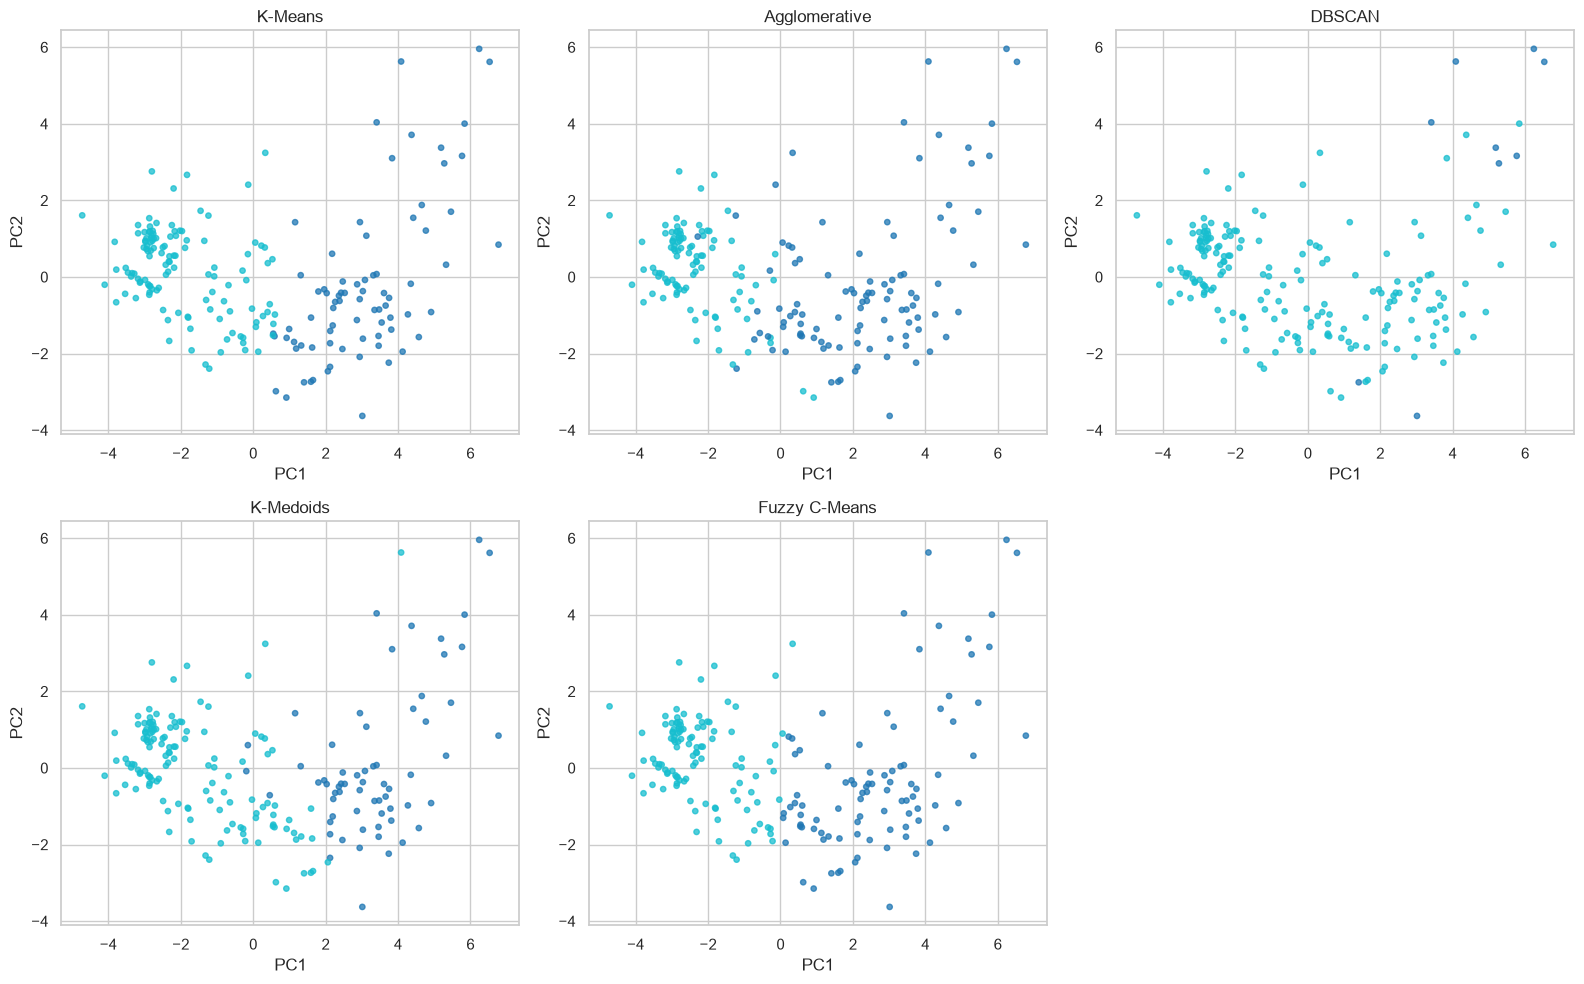

In [14]:
all_labels = {
    "K-Means": labels_kmeans,
    "Agglomerative": labels_hier,
    "DBSCAN": labels_dbscan,
    "K-Medoids": labels_kmedoids,
    "Fuzzy C-Means": labels_fcm
}
comparison_rows = []
for name, labels in all_labels.items():
    scores = evaluate_labels(X, labels, noise_label=-1 if name == "DBSCAN" else None)
    comparison_rows.append({
        "Algorithm": name,
        "Clusters (excluding noise)": len(set(labels) - ({-1} if name == "DBSCAN" else set())),
        "Noise Points": int(np.sum(np.asarray(labels) == -1)) if name == "DBSCAN" else 0,
        **scores
    })
comparison = pd.DataFrame(comparison_rows)
display(comparison.sort_values("Silhouette", ascending=False, na_position="last"))

for metric in ["Silhouette", "Calinski-Harabasz", "Davies-Bouldin"]:
    plt.figure(figsize=(10, 5))
    sns.barplot(data=comparison, x="Algorithm", y=metric)
    plt.title(f"Algorithm Comparison: {metric}")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (name, labels) in zip(axes.flat, all_labels.items()):
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", s=15, alpha=0.75)
    ax.set_title(name)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


In [15]:
display(comparison.sort_values("Silhouette", ascending=False, na_position="last").reset_index(drop=True))
print("\nSelected model settings")
print({
    "K-Means K": best_k,
    "Agglomerative K": best_hier_k,
    "DBSCAN eps": best_db_key[0],
    "DBSCAN min_samples": best_db_key[1],
    "K-Medoids K": best_medoid_k,
    "Fuzzy C-Means K": best_fcm_k
})


,Algorithm,Clusters (excluding noise),Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,K-Means,2,0,0.254255,61.673446,1.706262
1,K-Medoids,2,0,0.253793,55.142259,1.748933
2,Fuzzy C-Means,2,0,0.237440,61.367676,1.700688
3,Agglomerative,2,0,0.214337,56.048844,1.743951
4,DBSCAN,1,9,NaN,NaN,NaN



Selected model settings
{'K-Means K': 2, 'Agglomerative K': 2, 'DBSCAN eps': 6.401431472799867, 'DBSCAN min_samples': 10, 'K-Medoids K': 2, 'Fuzzy C-Means K': 2}
